<a href="https://colab.research.google.com/github/EthanJF-Physics/MAT422/blob/main/MAT422HW10EthanF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt


### 3.5 K-means

K-means clustering is a popular method of vector quantization that aims to partition $n$ observations into $k$ clusters, where each observation belongs to the cluster with the nearest mean (cluster center or cluster centroid). The centroid serves as a prototype of the cluster. K-means clustering minimizes within-cluster variances (squared Euclidean distances), rather than regular Euclidean distances.

Given the observations $(\mathbf{x}_1,\mathbf{x}_2,\dots,\mathbf{x}_n)$, where each observation is a $d$-dimensional real vector, K-means clustering aims to partition the $n$ observations into $k$ ($k<n$) sets $S=\{S_1,\dots,S_k\}$.

We wish to minimize the within-cluster sum of squares (WCSS), which is the sum of the squared distances of each vector from its corresponding centroid. For each cluster $S_i$, we define:

$$
\mathrm{WCSS}_i =
\sum_{\mathbf{x}\in S_i}
\|\mathbf{x}-\boldsymbol{\mu}(S_i)\|^2
$$

where $\boldsymbol{\mu}(S_i)$ is the mean of the points in $S_i$, given by:

$$
\boldsymbol{\mu}(S_i)
=
\frac{1}{|S_i|}
\sum_{\mathbf{x}\in S_i}\mathbf{x}
$$

The objective is to find a partition that minimizes the total within-cluster sum of squares:

$$
\arg\min_{S_1,\dots,S_k}
\sum_{i=1}^k \mathrm{WCSS}_i
$$

### K-means Clustering Algorithm

1. Define the number of clusters $k$.
2. Select $k$ points at random as initial cluster centers.
3. Assign observations to their closest cluster center according to the Euclidean distance function.
4. Calculate the centroid or mean of all observations in each cluster.
5. Repeat steps 3 and 4 until the cluster assignments no longer change or a predefined maximum number of iterations is reached.

### Calculating WCSS

To evaluate how well the observations are clustered, we calculate the total within-cluster sum of squares:

$$
WCSS =
\sum_{i=1}^{k}
\sum_{\mathbf{x}\in S_i}
\|\mathbf{x}-\boldsymbol{\mu}(S_i)\|^2
$$

A smaller WCSS indicates that observations are closer to their respective centroids. The K-means algorithm aims to minimize this value.

### Convergence of K-means

The K-means algorithm converges by monotonically decreasing or maintaining the WCSS during each iteration.

First, during the reassignment step, each observation is assigned to its closest centroid. Since every observation is assigned to the nearest centroid, its squared distance to its assigned centroid cannot increase. Therefore, the total WCSS decreases or remains unchanged.

Second, during the recomputation step, the centroid of each cluster is recalculated as the mean of all observations belonging to that cluster. This updates the centroid to represent the center of its assigned observations.

Consequently, the WCSS decreases or remains unchanged during the iterations.

We can express this property mathematically as:

$$
WCSS^{(t+1)} \leq WCSS^{(t)}
$$

where $t$ represents the iteration number.

Since there are only finitely many possible assignments of $n$ observations into $k$ clusters, the algorithm eventually terminates when the assignments no longer change. Hence, K-means converges to a local optimum, although it is not guaranteed to find the global minimum.


FINAL RESULTS:
Centroids Coordinates:
  Cluster 0: [1.93551314 2.11560314]
  Cluster 1: [5.71069413 5.79832953]
  Cluster 2: [6.93998628 0.84098257]

Cluster Distributions:
  Cluster 0: 98 points (32.7%)
  Cluster 1: 103 points (34.3%)
  Cluster 2: 99 points (33.0%)


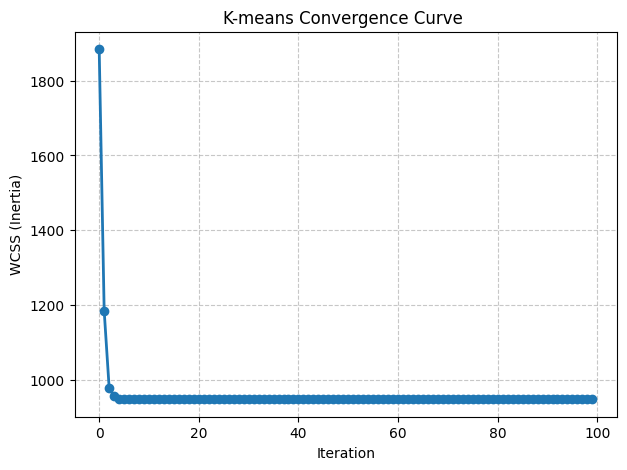

In [13]:
import numpy as np
import matplotlib.pyplot as plt

class kmeans:
    '''K: Number of clusters'''
    def __init__(self, K):
        assert K > 0
        self.K = K
    def initialize_centroids(self, X):
        assert X.shape[0] >= self.K
        randomized_X = np.random.permutation(X.shape[0])
        centroid_idx = randomized_X[:self.K]
        self.centroids = X[centroid_idx]
    def assign_points_centroids(self, X):
        distance = np.linalg.norm(
            X[:, np.newaxis, :] -
            self.centroids[np.newaxis, :, :],
            axis=2
        )
        points = np.argmin(distance, axis=1)
        return points
    def compute_mean(self, X, points):
        centroids = np.zeros((self.K, X.shape[1]))
        for i in range(self.K):
            cluster_points = X[points == i]
            if len(cluster_points) > 0:
                centroids[i] = np.mean(
                    cluster_points, axis=0
                )
            else:
                centroids[i] = self.centroids[i]
        return centroids
    def compute_WCSS(self, X, points):
        wcss = 0
        for i in range(self.K):
            cluster_points = X[points == i]
            if len(cluster_points) > 0:
                wcss += np.sum(
                    (cluster_points - self.centroids[i]) ** 2
                )
        return wcss
    def fit(self, X, iterations=100):
        self.initialize_centroids(X)
        self.wcss_history = []
        previous_points = None
        for i in range(iterations):
            points = self.assign_points_centroids(X)
            self.centroids = self.compute_mean(X, points)
            wcss = self.compute_WCSS(X, points)
            self.wcss_history.append(wcss)
            previous_points = points.copy()
        points = self.assign_points_centroids(X)
        return self.centroids, points

# Data
np.random.seed(0)
cluster1 = np.random.normal(loc=[2.0, 2.0], scale=1.2, size=(100, 2))
cluster2 = np.random.normal(loc=[6.0, 6.0], scale=1.5, size=(100, 2))
cluster3 = np.random.normal(loc=[7.0, 1.0], scale=1.2, size=(100, 2))
X = np.vstack([cluster1, cluster2, cluster3])

# Run K-means with K=3 clusters
model = kmeans(K=3)
centroids, labels = model.fit(X)
print("FINAL RESULTS:")
print("==================================================")
print("Centroids Coordinates:")
for idx, c in enumerate(centroids):
    print(f"  Cluster {idx}: {c}")
print("\nCluster Distributions:")
for i in range(model.K):
    count = np.sum(labels == i)
    percentage = (count / len(X)) * 100
    print(f"  Cluster {i}: {count} points ({percentage:.1f}%)")

# Plot WCSS convergence
plt.figure(figsize=(7, 5))
plt.plot(model.wcss_history, marker='o', color='#1f77b4', linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("WCSS (Inertia)")
plt.title("K-means Convergence Curve ")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()



### 3.6 Support vector machine

Support-vector machines (SVMs) are supervised learning models in machine learning that aim to analyze data for classification and regression tasks. Given a set of training examples, each marked as belonging to one of two categories, an SVM training algorithm builds a model that assigns new examples to one category or the other. The objective of a support vector machine is to find a hyperplane in a high-dimensional space of the number of features that distinctly classifies the data points. A SVM maps training examples to points in space so as to maximize the width of the gap between the two categories. Predictions of new data are based on which side of the gap they fall. Fig. 3.13 illustrates a hyperplane and its margins for an SVM trained with samples from two classes. The samples that lie on the margin are called the support vectors.

As shown in Fig. 3.13, we are given a training data set of \(n\) points of the form

$$
(\mathbf{x}_1,y_1),\dots,(\mathbf{x}_n,y_n),
$$

where \(y_i\in\{-1,1\}\), with each label indicating the class to which the point \(\mathbf{x}_i\) belongs. Each \(\mathbf{x}_i\) is a \(p\)-dimensional real vector. We wish to maximize the margin distance of the hyperplane that divides the group of points \(\mathbf{x}_i\) for which \(y_i=1\) from the group of points for which \(y_i=-1\). Maximizing the margin distance provides some reinforcement so that future data points can be classified with more confidence.

A hyperplane can be written as the set of points \(\mathbf{x}\) satisfying

$$
\mathbf{w}^T\mathbf{x}-b=0,
$$

where \(\mathbf{w}\) is the normal vector to the hyperplane and \(b\) is a scalar parameter. If the training data is linearly separable, we can select two parallel hyperplanes that separate the two classes of data, so that the distance between them is as large as possible. The region bounded by these two hyperplanes is called the margin, and the maximum-margin hyperplane is the hyperplane that lies halfway between them, as illustrated in Fig. 3.13.

We are interested in two regions: anything on or above this boundary is one of the classes, with label \(1\), and anything on or below this boundary is of the other class, with label \(-1\). The two hyperplanes can be respectively described by the equations

$$
\mathbf{w}^T\mathbf{x}-b=1
$$

and

$$
\mathbf{w}^T\mathbf{x}-b=-1.
$$

We wish all data points to fall into the margin, which can be expressed as follows. For each \(i\), we require either

$$
\mathbf{w}^T\mathbf{x}_i-b\geq 1,
\qquad \text{if } y_i=1,
$$

or

$$
\mathbf{w}^T\mathbf{x}_i-b\leq -1,
\qquad \text{if } y_i=-1.
$$

Combining these two constraints, we obtain

$$
y_i(\mathbf{w}^T\mathbf{x}_i-b)\geq 1,
\qquad \text{for all } 1\leq i\leq n.
$$

The distance between the two parallel hyperplanes is \(2/\|\mathbf{w}\|\). Thus, maximizing the margin is equivalent to minimizing \(\|\mathbf{w}\|\). Instead of minimizing the norm directly, we minimize its square, which gives a convenient differentiable objective function.

In practice, the data may not be perfectly linearly separable. To account for this, we introduce a penalty for observations that violate the margin constraints. This penalty is given by the hinge loss function

$$
\max\{0,1-y_i(\mathbf{w}^T\mathbf{x}_i-b)\}.
$$

If an observation satisfies the margin constraint, the hinge loss is zero. Otherwise, the loss measures the extent to which the observation violates the margin.

We can now formulate the optimization problem. The goal of the optimization is to minimize the regularization term and the average hinge loss:

$$
\min_{\mathbf{w},b}
\left(
\lambda\|\mathbf{w}\|^2
+
\frac{1}{n}\sum_{i=1}^n
\max\{0,1-y_i(\mathbf{w}^T\mathbf{x}_i-b)\}
\right).
$$

The first term, \(\lambda\|\mathbf{w}\|^2\), is called the regularization term, while the second term is the error term. The parameter \(\lambda\) adjusts the trade-off between increasing the margin size and ensuring that the observations lie on the correct side of the margin. A larger value of \(\lambda\) places more emphasis on minimizing the norm of \(\mathbf{w}\), while a smaller value places more emphasis on minimizing the classification errors.

In principle, the unconstrained optimization problem can be directly solved by gradient descent methods. Because this function is convex in \(\mathbf{w}\) and \(b\), we can apply gradient-based optimization methods to find a global minimum.

To apply gradient descent, we first consider the hinge loss for an individual observation:

$$
\ell_i(\mathbf{w},b)
=
\max\{0,1-y_i(\mathbf{w}^T\mathbf{x}_i-b)\}.
$$

We distinguish two cases. If

$$
1-y_i(\mathbf{w}^T\mathbf{x}_i-b)>0,
$$

the observation violates the margin constraint, and the hinge loss is positive. Otherwise, the hinge loss is zero and does not contribute to the gradient.

For the first case, the derivative of the hinge loss with respect to \(b\) is

$$
\frac{\partial \ell_i}{\partial b}
=
y_i.
$$

For the second case, the derivative is zero. Similarly, the gradient with respect to \(\mathbf{w}\) is

$$
\nabla_{\mathbf{w}}\ell_i
=
-y_i\mathbf{x}_i
$$

when the margin constraint is violated, and zero otherwise.

Taking into account the regularization term, we obtain

$$
\nabla_{\mathbf{w}}
\left(\lambda\|\mathbf{w}\|^2\right)
=
2\lambda\mathbf{w}.
$$

Thus, the gradient of the objective function with respect to \(\mathbf{w}\) is

$$
\nabla_{\mathbf{w}}\ell(\mathbf{w},b)
=
2\lambda\mathbf{w}
-
\frac{1}{n}
\sum_{i=1}^n
y_i\mathbf{x}_i
\mathbb{1}
\left\{
1-y_i(\mathbf{w}^T\mathbf{x}_i-b)>0
\right\},
$$

where \(\mathbb{1}\{\cdot\}\) denotes the indicator function, which equals one when the condition is satisfied and zero otherwise.

Similarly, the gradient with respect to \(b\) is

$$
\frac{\partial \ell(\mathbf{w},b)}{\partial b}
=
\frac{1}{n}
\sum_{i=1}^n
y_i
\mathbb{1}
\left\{
1-y_i(\mathbf{w}^T\mathbf{x}_i-b)>0
\right\}.
$$

In stochastic gradient descent, a variant of gradient descent, we select an index \(i\) uniformly at random from \(\{1,\dots,n\}\) and update the parameters using the gradient corresponding to that observation. For step size \(\beta\), the update for \(b\) is

$$
b^{k+1}
=
b^k-\beta
\begin{cases}
y_i, & \text{if }1-y_i((\mathbf{w}^k)^T\mathbf{x}_i-b^k)>0,\\
0, & \text{otherwise}.
\end{cases}
\tag{3.6.1}
$$

Similarly, the update for \(\mathbf{w}\) is

$$
\mathbf{w}^{k+1}
=
\mathbf{w}^k-\beta
\begin{cases}
2\lambda\mathbf{w}^k-y_i\mathbf{x}_i,
& \text{if }1-y_i((\mathbf{w}^k)^T\mathbf{x}_i-b^k)>0,\\
2\lambda\mathbf{w}^k,
& \text{otherwise}.
\end{cases}
\tag{3.6.2}
$$

These updates show that when an observation violates the margin constraint, the parameters are adjusted to reduce the hinge loss while also accounting for regularization. When the observation satisfies the margin constraint, only the regularization term contributes to the update of \(\mathbf{w}\), while \(b\) remains unchanged.


Weights:
[0.25911802 1.8412785 ]

Bias:
-0.004

Predictions:
[-1 -1 -1 -1 -1 -1  1  1  1 -1  1  1 -1 -1  1  1  1  1  1  1 -1 -1 -1 -1
  1 -1 -1  1  1  1 -1  1  1 -1 -1  1  1  1 -1  1 -1  1  1  1 -1 -1  1 -1
  1 -1 -1  1 -1 -1  1  1  1  1 -1 -1]

Test Accuracy:
85.0 %

Average Training Hinge Loss:
0.23594731577880854

Training Objective Function:
0.2705218025476314

Approximate Number of Support Vectors:
84


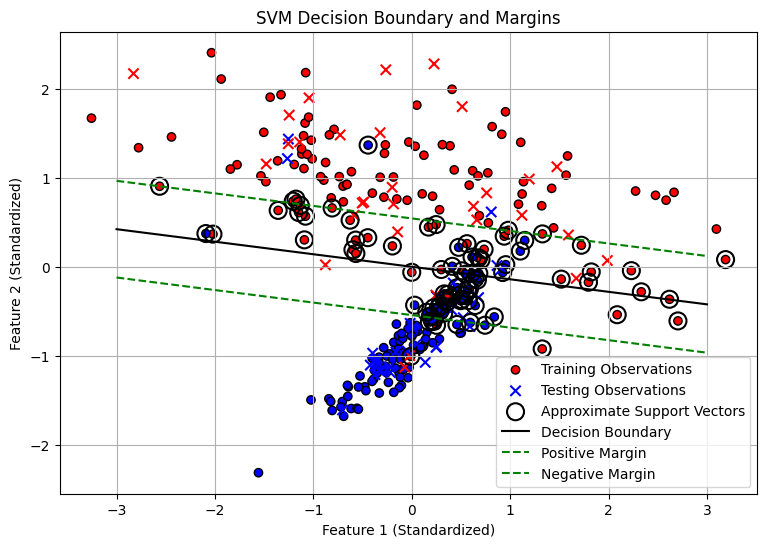

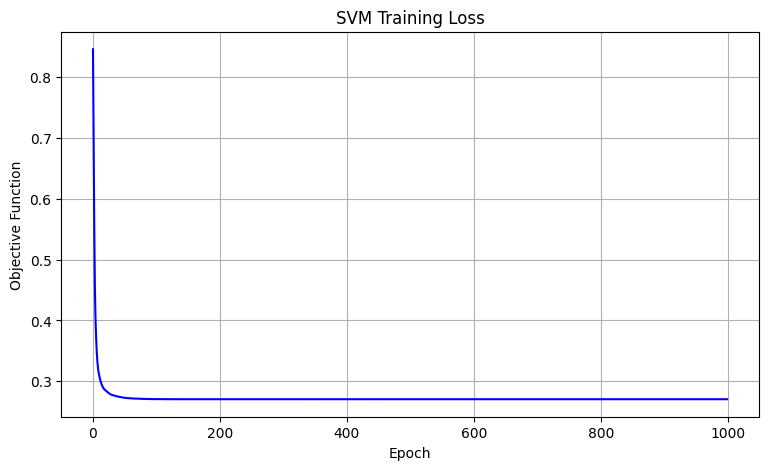

In [14]:
# Imports
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_classification(
    n_samples=300,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=1,
    class_sep=1.0,
    flip_y=0.04,
    random_state=42
)
y = np.where(y == 0, -1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

class SVM:
    def __init__(self, learning_rate=0.001,
                 lambda_param=0.01, epochs=1000):
        self.lr = learning_rate
        self.lambda_param = lambda_param
        self.epochs = epochs
        self.w = None
        self.b = None
    def decision_function(self, X):
        return np.dot(X, self.w) - self.b
    def predict(self, X):
        predictions = self.decision_function(X)
        return np.where(predictions >= 0, 1, -1)
    def compute_hinge_loss(self, X, y):
        distances = y * self.decision_function(X)
        return np.maximum(0, 1 - distances)
    def compute_loss(self, X, y):
        hinge_loss = self.compute_hinge_loss(X, y)
        regularization = (
            self.lambda_param * np.dot(self.w, self.w)
        )
        return regularization + np.mean(hinge_loss)
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []
        for epoch in range(self.epochs):
            # Randomize observation order
            indices = np.random.permutation(n_samples)
            for idx in indices:
                x_i = X[idx]
                y_i = y[idx]
                # Calculate margin
                condition = y_i * (
                    np.dot(x_i, self.w) - self.b
                )
                # Update parameters
                if condition < 1:
                    self.w -= self.lr * (
                        2 * self.lambda_param * self.w
                        - y_i * x_i
                    )
                    self.b -= self.lr * y_i
                else:
                    self.w -= self.lr * (
                        2 * self.lambda_param * self.w
                    )
            self.loss_history.append(
                self.compute_loss(X, y)
            )
        return self
    def get_support_vectors(self, X, y, tolerance=0.1):
        margins = y * self.decision_function(X)
        return X[margins <= 1 + tolerance]

# Train
np.random.seed(42)
model = SVM(
    learning_rate=0.001,
    lambda_param=0.01,
    epochs=1000
)
model.fit(X_train, y_train)
print("Weights:")
print(model.w)
print("\nBias:")
print(model.b)
predictions = model.predict(X_test)
accuracy = np.mean(predictions == y_test)
print("\nPredictions:")
print(predictions)
print("\nTest Accuracy:")
print(accuracy * 100, "%")
hinge_loss = model.compute_hinge_loss(
    X_train, y_train
)
total_loss = model.compute_loss(
    X_train, y_train
)
print("\nAverage Training Hinge Loss:")
print(np.mean(hinge_loss))
print("\nTraining Objective Function:")
print(total_loss)
support_vectors = model.get_support_vectors(
    X_train, y_train
)
print("\nApproximate Number of Support Vectors:")
print(len(support_vectors))

# Visualize
plt.figure(figsize=(9, 6))
plt.scatter(
    X_train[:, 0], X_train[:, 1],
    c=y_train,
    cmap='bwr',
    edgecolors='k',
    label='Training Observations'
)
plt.scatter(
    X_test[:, 0], X_test[:, 1],
    c=y_test,
    cmap='bwr',
    marker='x',
    s=55,
    label='Testing Observations'
)
plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=150,
    facecolors='none',
    edgecolors='black',
    linewidths=1.5,
    label='Approximate Support Vectors'
)
x_values = np.linspace(
    -3, 3, 200
)
if abs(model.w[1]) > 1e-10:
    decision_boundary = (
        model.b - model.w[0] * x_values
    ) / model.w[1]
    positive_margin = (
        model.b + 1 - model.w[0] * x_values
    ) / model.w[1]
    negative_margin = (
        model.b - 1 - model.w[0] * x_values
    ) / model.w[1]
    plt.plot(
        x_values, decision_boundary,
        'k-', label='Decision Boundary'
    )
    plt.plot(
        x_values, positive_margin,
        'g--', label='Positive Margin'
    )
    plt.plot(
        x_values, negative_margin,
        'g--', label='Negative Margin'
    )
elif abs(model.w[0]) > 1e-10:
    boundary_x = model.b / model.w[0]
    positive_x = (model.b + 1) / model.w[0]
    negative_x = (model.b - 1) / model.w[0]
    plt.axvline(
        boundary_x,
        color='black',
        label='Decision Boundary'
    )
    plt.axvline(
        positive_x,
        color='green',
        linestyle='--',
        label='Positive Margin'
    )
    plt.axvline(
        negative_x,
        color='green',
        linestyle='--',
        label='Negative Margin'
    )
plt.xlabel("Feature 1 (Standardized)")
plt.ylabel("Feature 2 (Standardized)")
plt.title("SVM Decision Boundary and Margins")
plt.legend()
plt.grid(True)
plt.show()

# Visualize Training Convergence
plt.figure(figsize=(9, 5))
plt.plot(
    model.loss_history,
    color='blue'
)
plt.xlabel("Epoch")
plt.ylabel("Objective Function")
plt.title("SVM Training Loss")
plt.grid(True)
plt.show()